# Optimización Bayesiana

**Teorema de Bayes**

$$ P(A|B) = \frac{P(B|A) P(A)}{P(B)} $$

$ P(A|B) $: Probabilidad condicional de A dado B. También conocida como la probabilidad posterior de A dado que B ocurre.

$ P(B|A) $: Probabilidad condicional de B dado A. Se interpreta como la verosimilitud (*likelihood*) de A.

$ P(A) $: Probabilidad de observar A. También conocida como probabilidad a priori.

$ P(B) $: Probabilidad de observar B. Interpretada como evidencia.

Utilizando las definiciones de arriba actualizamos la definición del teorema de bayes:

$$ \text{posterior} = \frac{(\text{verosimilitud})(\text{anterior})}{\text{evidencia}} $$

La intuición es que el teorema de Bayes es una herramienta para actualizar nuestras creencias dado lo que se tenía antes y nueva evidencia. Por ejemplo, tomas una moneda y asumes que es una moneda justa, dado que es lo más probable y que las monedas suelen ser justas en tu experiencia. Lanzas la moneda tres veces y cae sello las tres veces; un poco extraño, así que ajustas tus creencias y empiezas a imaginar que la moneda no es tan justa como debería ser. Lanzas las monedas tres veces y cae águila; ahora crees que la moneda es justa de nuevo.

## ¿Cómo aplicamos esto en nuestra vida diaria?

Imagina que tienes 3 puntos (conocimiento previo) en un espacio.

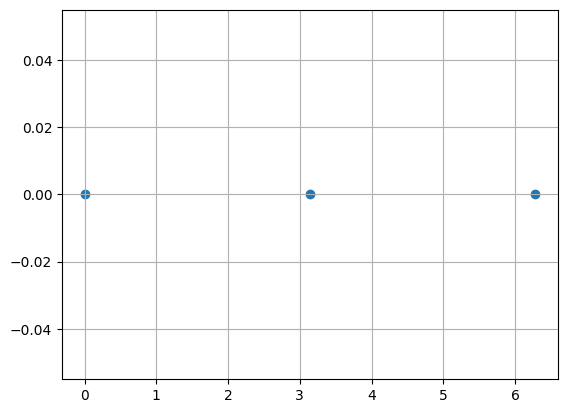

In [1]:
import matplotlib.pyplot as plt
import numpy as np
plt.figure(); plt.scatter([0, np.pi, 2*np.pi], [0, 0, 0]); plt.grid()

No hay seguridad de cómo se conectan estos puntos, pero sabes que están conectados. Hay infinitas formas en las que estos puntos se pueden conectar.

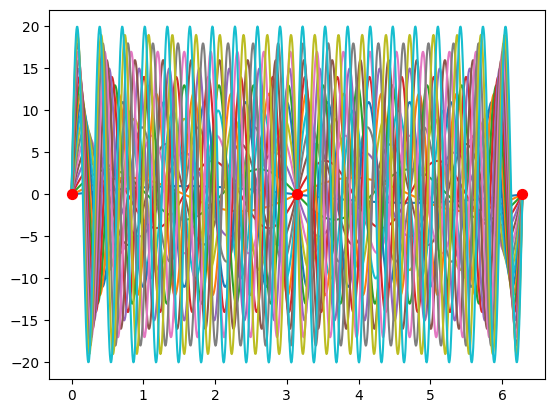

In [2]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(20) :
    y = (i+1)*np.sin((i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi], [0, 0, 0], s=50, c="r", zorder=3)

Hay tanta incertidumbre que decides pedir más información y te dan otro punto.

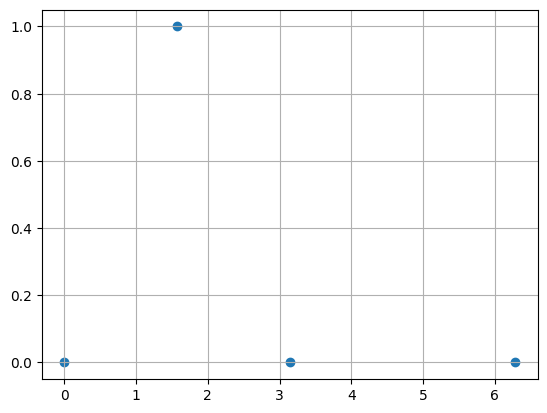

In [3]:
plt.figure(); plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1]); plt.grid()

Con esta nueva información actualizas tus creencias y reduces la cantidad de formas en las que se conectan estos puntos (siguen siendo infinitas).

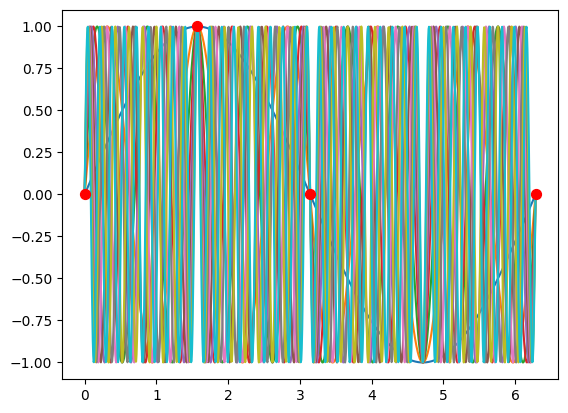

In [4]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(10) :
    y = np.sin((4*i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1], s=50, c="r", zorder=3)

Te pones a pensar: "Sí. Teóricamente hay infinitas funciones que pueden conectar estos puntos, pero sólo algunas tienen sentido dado mi contexto."

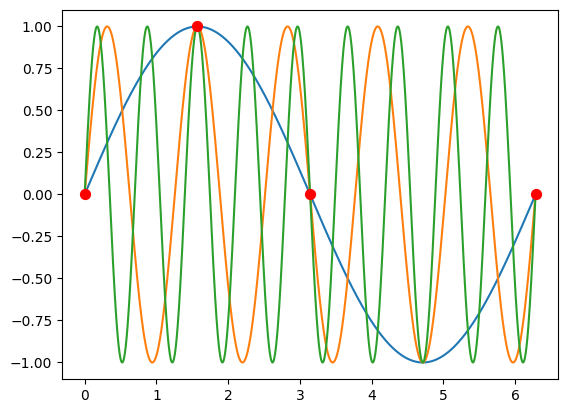

In [5]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(3) :
    y = np.sin((4*i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1], s=50, c="r", zorder=3)

Ahora sólo quedan algunos pocos candidatos dado el criterio que tienes. Hay incertidumbre sobre cuál de estos candidatos podría ser el que mejor se ajusta, así que decides pedir más información. ¿Qué información serviría más?
- Se podría pedir el valor de $y$ cuando $x=\frac{3\pi}{2}$, pero los candidatos que tenemos todos pasan por el mismo punto. Incluso si nos dieran la información, no ayudaría de mucho.
- Se podría pedir fuera del rango que tenemos, pero quizás la información no existe o dado el contexto del problema es imposible que estos puntos existan.

Nos asignan nuestro último punto.

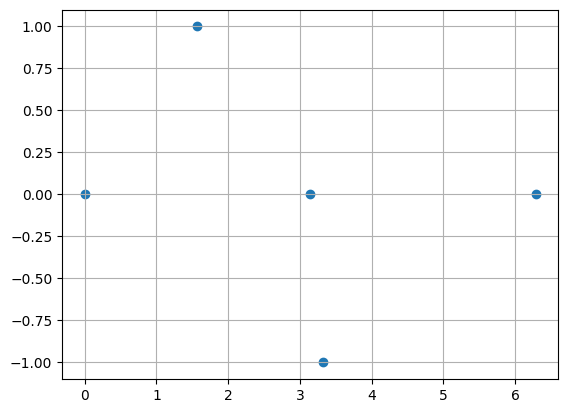

In [6]:
plt.figure(); plt.scatter([0, np.pi, 2*np.pi, np.pi/2, 19*np.pi/18], [0, 0, 0, 1, -1]); plt.grid()

Usamos esta nueva información (evidencia) junto con lo que conocíamos (anterior) y lo que creemos que es posible (verosimilitud) para decidir sobre una nueva función (posterior).

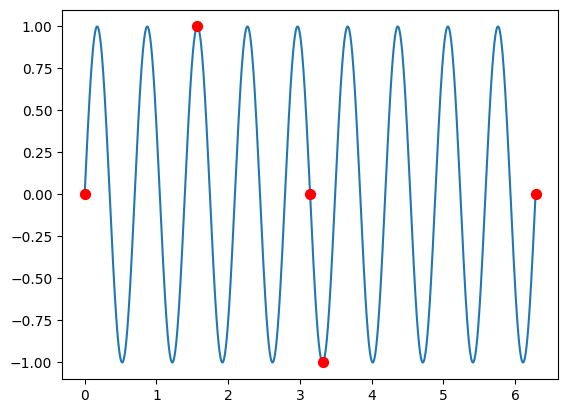

In [7]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); y = np.sin(9*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2, 19*np.pi/18], [0, 0, 0, 1, -1], s=50, c="r", zorder=3)

Una forma de realizar este experimento es mediante un proceso gaussiano, que asume que la variable de salida es una variable aleatoria con distribución normal multivariada. Utilicemos la función que encontramos y asumamos que no sabemos cuál es.

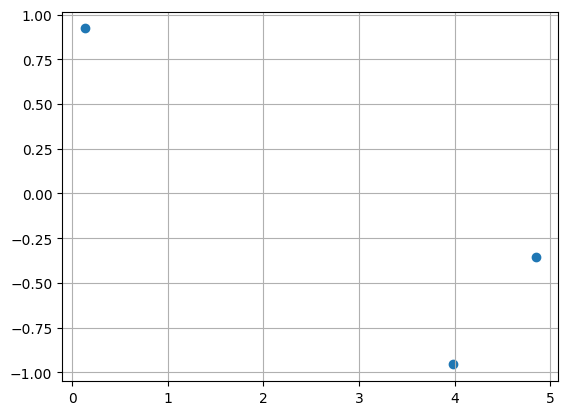

In [8]:
np.random.seed(10)
def f(x) :
    return np.sin(9*x)
X = np.random.uniform(0, 2*np.pi, 3).reshape([-1, 1])
plt.figure(); plt.scatter(X, f(X)); plt.grid()

Realizamos una regresión de proceso gaussiano para encontrar distribuciones que podrían darnos estas muestras

In [9]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
import numpy as np

In [10]:
kernel = 1.0*RBF(length_scale=1.0)
gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
X
y = f(X)

In [11]:
gp.fit(X, y)

,kernel,1**2 * RBF(length_scale=1)
,alpha,1e-10
,optimizer,'fmin_l_bfgs_b'
,n_restarts_optimizer,10
,normalize_y,False
,copy_X_train,True
,n_targets,None
,random_state,None
,kernel__k1,1**2
,kernel__k2,RBF(length_scale=1)
,kernel__k1__constant_value,1.0


In [12]:
X_new = np.linspace(0, 2*(np.pi), 10000).reshape(-1, 1)

y_pred, desv = gp.predict(X_new, return_std=True)

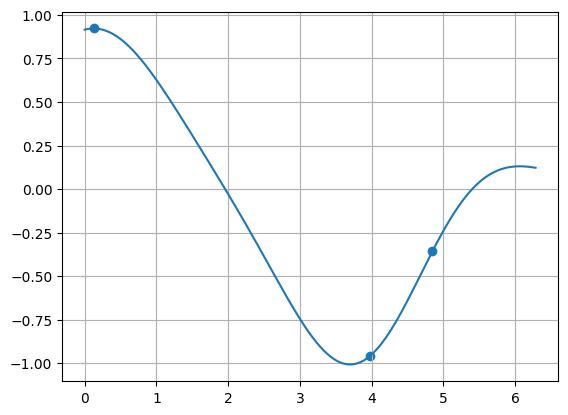

In [13]:
plt.figure()
plt.plot(X_new, y_pred)
plt.scatter(X, f(X))
plt.grid()
plt.show()

In [14]:
y_upper = y_pred + 2*desv
y_lower = y_pred - 2*desv

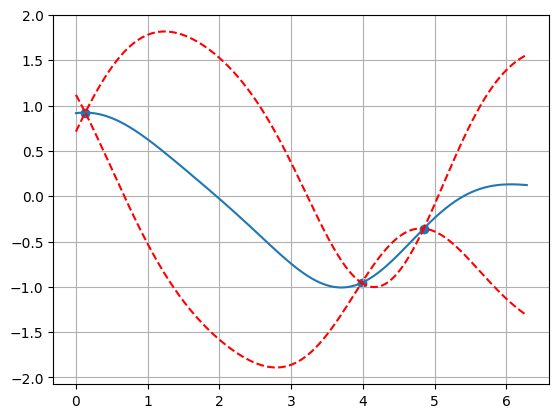

In [15]:
plt.figure()
plt.plot(X_new, y_pred)
plt.plot(X_new, y_upper, color="red", linestyle="--")
plt.plot(X_new, y_lower, color="red", linestyle="--")
plt.scatter(X, f(X))
plt.grid()
plt.show()

Podemos ver que necesitamos más muestras debido a que hay mucha incertidumbre en algunas partes de nuestro dominio. Hay varios criterios para decidir cómo pedir muestras:
- Maximizar (busco mi predicción del máximo actual y pido esa medida)
- Minimizar (busco mi predicción del mínimo actual y pido esa medida)
- Reducir incertidumbre (busco el punto donde mi intervalo de confianza es más grande y pido esa medida)

Repitamos el proceso 30 veces con una función distinta.

$$ f(x) = \sin{(\frac{x}{3})} + \cos{(2x)},\ \ \ \ x \in [-5\pi, 5\pi] $$

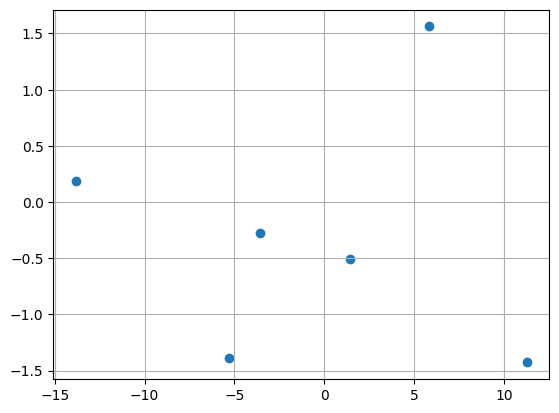

In [16]:
def f(x): 
    return np.sin(x/3) + np.cos(2*x)
np.random.seed(67)
X_2 = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape(-1, 1)
X_ini = X_2.copy()
plt.figure(); plt.scatter(X_2, f(X_2)); plt.grid()

In [17]:
X_new_2 = np.linspace(-5*np.pi, 5*np.pi, 10000).reshape(-1, 1)

kernel_2 = 1.0*RBF(length_scale=1.0)
gp2 = GaussianProcessRegressor(kernel=kernel_2, n_restarts_optimizer=10)
gp2.fit(X_2, f(X_2))
y_pred_2, desv_2 = gp2.predict(X_new_2, return_std=True)
y_upper_2 = y_pred_2 + 2*desv_2
y_lower_2 = y_pred_2 - 2*desv_2

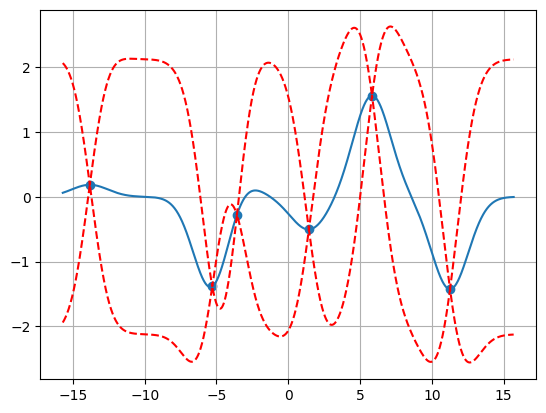

In [18]:
plt.figure()
plt.plot(X_new_2, y_pred_2)
plt.plot(X_new_2, y_upper_2, color="red", linestyle="--")
plt.plot(X_new_2, y_lower_2, color="red", linestyle="--")
plt.scatter(X_2, f(X_2))
plt.grid()
plt.show()

In [19]:
X_2 = X_ini.copy()

for i in range(30):
    gp2 = GaussianProcessRegressor(kernel=1.0*RBF(length_scale=1.0), n_restarts_optimizer=10)
    gp2.fit(X_2, f(X_2))
    y_upper_2 = y_pred_2 + 2*desv_2
    x_sig = X_new_2[np.argmax(y_upper_2)]
    X_2 = np.vstack([X_2, x_sig])

print("Muestras totales:", len(X_2))

C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 17 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 13 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gau

Muestras totales: 36


In [20]:
gp2 = GaussianProcessRegressor(kernel=1.0*RBF(length_scale=1.0), n_restarts_optimizer=10)
gp2.fit(X_2, f(X_2))
y_pred_2, desv_2 = gp2.predict(X_new_2, return_std=True)
y_upper_2 = y_pred_2 + 2*desv_2
y_lower_2 = y_pred_2 - 2*desv_2

C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 4 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


C:\Users\ceciq\AppData\Local\Temp\ipykernel_7492\4265402050.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


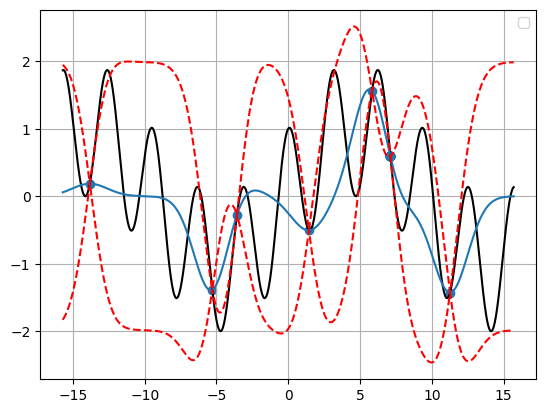

In [21]:
plt.figure()
plt.plot(X_new_2, f(X_new_2), color="black")
plt.plot(X_new_2, y_pred_2)
plt.plot(X_new_2, y_upper_2, color="red", linestyle="--")
plt.plot(X_new_2, y_lower_2, color="red", linestyle="--")
plt.scatter(X_2, f(X_2))
plt.legend()
plt.grid()
plt.show()

### Actividad

1. Modificar el comportamiento de selección para elegir el máximo de las predicciones como el siguiente punto.
2. Modificar el comportamiento de selección para elegir el mínimo de las predicciones como el siguiente punto.

**Máximo**

In [22]:
X_max = X_ini.copy()

for i in range(30):
    gp2 = GaussianProcessRegressor(kernel=1.0*RBF(length_scale=1.0), n_restarts_optimizer=10)
    gp2.fit(X_max, f(X_max))
    y_pred_2, desv_2 = gp2.predict(X_new_2, return_std=True)
    x_sig = X_new_2[np.argmax(y_pred_2)]
    X_max = np.vstack([X_max, x_sig])

print("Muestras totales:", len(X_max))

C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gauss

Muestras totales: 36


In [23]:
gp2 = GaussianProcessRegressor(kernel=1.0*RBF(length_scale=1.0), n_restarts_optimizer=10)
gp2.fit(X_max, f(X_max))
y_pred_2, desv_2 = gp2.predict(X_new_2, return_std=True)
y_upper_2 = y_pred_2 + 2*desv_2
y_lower_2 = y_pred_2 - 2*desv_2

C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gauss

C:\Users\ceciq\AppData\Local\Temp\ipykernel_7492\3281984078.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


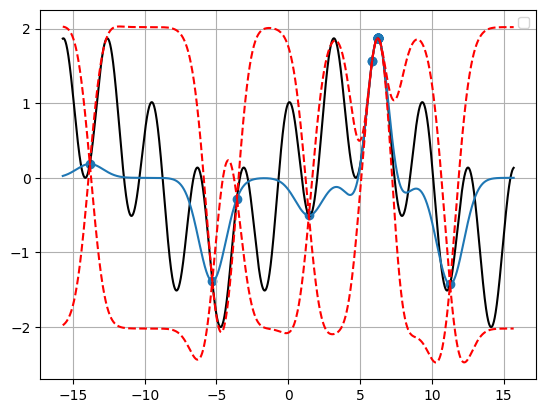

In [24]:
plt.figure()
plt.plot(X_new_2, f(X_new_2), color="black")
plt.plot(X_new_2, y_pred_2)
plt.plot(X_new_2, y_upper_2, color="red", linestyle="--")
plt.plot(X_new_2, y_lower_2, color="red", linestyle="--")
plt.scatter(X_max, f(X_max))
plt.legend()
plt.grid()
plt.show()

**Mínimo**

In [25]:
X_min = X_ini.copy()

for i in range(30):
    gp2 = GaussianProcessRegressor(kernel=1.0*RBF(length_scale=1.0), n_restarts_optimizer=10)
    gp2.fit(X_min, f(X_min))
    y_pred_2, desv_2 = gp2.predict(X_new_2, return_std=True)
    x_sig = X_new_2[np.argmin(y_pred_2)]
    X_min = np.vstack([X_min, x_sig])

print("Muestras totales:", len(X_min))

C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 2 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gauss

Muestras totales: 36


In [26]:
gp2 = GaussianProcessRegressor(kernel=1.0*RBF(length_scale=1.0), n_restarts_optimizer=10)
gp2.fit(X_min, f(X_min))
y_pred_2, desv_2 = gp2.predict(X_new_2, return_std=True)
y_upper_2 = y_pred_2 + 2*desv_2
y_lower_2 = y_pred_2 - 2*desv_2

C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\_gpr.py:663: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


C:\Users\ceciq\AppData\Local\Temp\ipykernel_7492\3946510590.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


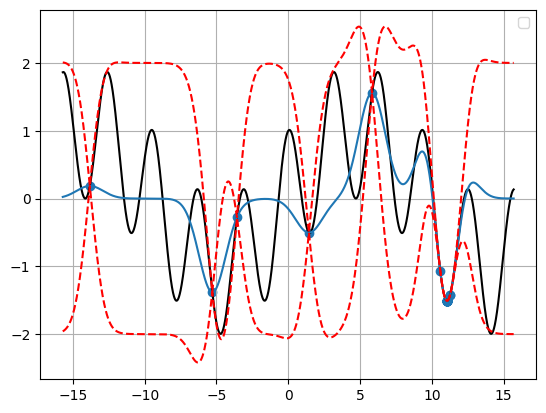

In [27]:
plt.figure()
plt.plot(X_new_2, f(X_new_2), color="black")
plt.plot(X_new_2, y_pred_2)
plt.plot(X_new_2, y_upper_2, color="red", linestyle="--")
plt.plot(X_new_2, y_lower_2, color="red", linestyle="--")
plt.scatter(X_min, f(X_min))
plt.legend()
plt.grid()
plt.show()

# **Optuna**

In [41]:
import pandas as pd
import optuna
from sklearn.svm import SVC
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

In [32]:
df = pd.read_csv('Default.csv')

In [33]:
df.head()

,rownames,default,student,balance,income
0,1,No,No,729.526495,44361.625074
1,2,No,Yes,817.180407,12106.134700
2,3,No,No,1073.549164,31767.138947
3,4,No,No,529.250605,35704.493935
4,5,No,No,785.655883,38463.495879


In [34]:
df = df.drop(columns=["rownames"])

In [35]:
df["default"] = (df["default"] == "Yes").astype(int)
df["student"] = (df["student"] == "Yes").astype(int)

In [36]:
df.head()

,default,student,balance,income
0,0,0,729.526495,44361.625074
1,0,1,817.180407,12106.134700
2,0,0,1073.549164,31767.138947
3,0,0,529.250605,35704.493935
4,0,0,785.655883,38463.495879


In [37]:
X = df[["student", "balance", "income"]]
y = df["default"]

In [ ]:
X = StandardScaler().fit_transform(X)

In [46]:
def objetivo(H):
    C = H[0]
    gamma = H[1]

    modelo = SVC(C=C, gamma=gamma, kernel='rbf')
    kf = KFold(n_splits=5)
    scores = cross_val_score(modelo, X, y, cv=kf, scoring='roc_auc')
    return np.mean(scores)

In [47]:
C = 1
gamma = 0.01

H = [C, gamma]
objetivo(H)

np.float64(0.8771588079424919)

In [50]:
H = [
    [1, 0.01],
    [0.0001, 2],
    [0.1, 1],
    [0.01, 100],
    [1, 10]                
]
scores = []
for pair in H :
    scores.append(objetivo(pair))

In [51]:
scores

[np.float64(0.8771588079424919),
 np.float64(0.5767956778253902),
 np.float64(0.6926226518578573),
 np.float64(0.6402817588680798),
 np.float64(0.6508376420504498)]

In [52]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

In [70]:
for i in range(30):
    kernel=1.0*RBF(length_scale=1.0)
    gp = GaussianProcessRegressor(kernel, n_restarts_optimizer=10)
    gp.fit(H, scores)
    H_sim = np.random.uniform(0.001, 1, size=[10000, 2])
    y_pred, desv = gp.predict(H_sim, return_std=True)
    y_upper = y_pred + 2*desv
    H_sim_max = H_sim[np.argmax(y_upper)]
    s = objetivo(H_sim_max)
    H.append(H_sim_max)
    scores.append(s)

C:\Users\ceciq\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\gaussian_process\kernels.py:440: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [73]:
print('Mejor resultado para C y gamma:', H[np.argmax(scores)])

Mejor resultado para C y gamma: [0.01985657 0.00259355]


In [75]:
print('Mejor score:', max(scores))

Mejor score: 0.9031981070164588
